In [2]:
import pandas as pd #Data manipulation and analysis (DataFrames/Series)
import numpy as np #High-performance numerical computing and array operations
import scipy.stats as sc #Advanced statistical functions and probability distributions
import statistics as st #Python's built-in module for basic descriptive statistics
import matplotlib.pyplot as plt #Core plotting library for creating data visulizations
from pathlib import Path #Modern, object-oriented file system path handling
from scipy.stats import trim_mean # Specific function to calculate trimmed-mean
import seaborn as sns #Statistical data visulization library built on top of Matplotlib

In [3]:
try:
    import common #Attempt to import a custom,shared utility module named 'common'
    DATA = common.dataDirectory() #If successful, fetch centralized data directory path defined path by that module
except ImportError:
     #If 'common' is missing (e.g., running the script standalone or in a different enviroment),
    #gracefully fall back to a local 'data' folder in the current working directory
    DATA=Path().resolve()/'data'

In [4]:
IU_internet_csv = DATA / 'IU_internet.csv'

In [5]:
print(Path().resolve()) #Print the absolute path of the directory where the current Python script is running
print(DATA) #Print the path stored in the DATA variable (either from 'common.py' or the local 'data'folder fallback) )
print(DATA.exists())#Check whether the directory path stored in DATA actually exists on the file system (returns True or False)

file_path = DATA / 'IU_internet.csv'# Construct the full path to a specific data file ('IU_internet.csv') inside the DATA directory
print(file_path.exists())#Check whether 'IU_internet.csv' actually exists at that location (returns True of False)

C:\Users\LENOVO\EDA1_IUinternet
C:\Users\LENOVO\EDA1_IUinternet\data
False
False


In [6]:
Share_with_internet = pd.read_csv("C:/Users/LENOVO/EDA1_IUinternet/IU_internet.csv")
print(Share_with_internet.head())

        Entity Code  Year  Share of the population using the Internet
0  Afghanistan  AFG  1990                                    0.000000
1  Afghanistan  AFG  2001                                    0.004723
2  Afghanistan  AFG  2002                                    0.004561
3  Afghanistan  AFG  2003                                    0.087891
4  Afghanistan  AFG  2004                                    0.105809


In [7]:
print('Mean value of share internet: ',Share_with_internet['Share of the population using the Internet'].mean())
print('Median value of share internet: ',Share_with_internet['Share of the population using the Internet'].median())
print('Trimmed mean value of share internet: ',trim_mean(Share_with_internet['Share of the population using the Internet'],0.1))
print('Standard deviation value of share internet: ',Share_with_internet['Share of the population using the Internet'].std())
print('Min value of share internet: ',Share_with_internet['Share of the population using the Internet'].min())
print('Max value of share internet: ',Share_with_internet['Share of the population using the Internet'].max())

Mean value of share internet:  32.6491316740425
Median value of share internet:  20.81
Trimmed mean value of share internet:  29.37871292155902
Standard deviation value of share internet:  32.54073167630182
Min value of share internet:  0.0
Max value of share internet:  100.0


In [8]:
print('Trimmed mean value of share internet: ',trim_mean(Share_with_internet['Share of the population using the Internet'],0.2))

Trimmed mean value of share internet:  26.30601721281961


In [9]:
print('Trimmed mean value of share internet: ',trim_mean(Share_with_internet['Share of the population using the Internet'],0.3))

Trimmed mean value of share internet:  23.36487156142589


In [10]:
print(Share_with_internet['Year'].min())
print(Share_with_internet['Year'].max())

1990
2025


In [11]:
print(Share_with_internet['Share of the population using the Internet'].describe())

count    6659.000000
mean       32.649132
std        32.540732
min         0.000000
25%         2.091550
50%        20.810000
75%        62.535350
max       100.000000
Name: Share of the population using the Internet, dtype: float64


In [12]:
def calculate_mad_mean(data):
    arr = np.array(data)#Convert the input data (list, tuple, etc.) into a NumPy array for fast vector math
    mean_val = np.mean(arr)#Calculate the arithmetic mean of the array
    abs_deviations = np.abs(arr-mean_val)#Compute the absolute distance of every data point from the mean (vectorized operation)
    mad = np.mean(abs_deviations) #Calculate the Mean Absolute Deviation (MAD) by taking the average of those absolute deviations
    return mean_val,mad #Return both the calculated mean and the MAD value as a tuple

In [13]:
#Extract a specific column ('Share of the population using the Internet') from the DataFrame
#and assign it to the variable MAD_mean for statistical analysis
MAD_mean = Share_with_internet['Share of the population using the Internet']
#Call the custom function you defined earlier, passing the data series.
#This function calculates both the mean and the Mean Absolute Deviation(MAD),
#then unpacks the two returned values into separate variables.
mean_result,mad_result = calculate_mad_mean(MAD_mean)
print(f"Data:{MAD_mean}")
print(f"Mean:{mean_result:.2f}")
print(f"Mean Absolute Deviation(MAD):{mad_result:.2f}")

Data:0        0.000000
1        0.004723
2        0.004561
3        0.087891
4        0.105809
          ...    
6654    29.298565
6655    32.592400
6656    36.256500
6657    38.674800
6658    41.642800
Name: Share of the population using the Internet, Length: 6659, dtype: float64
Mean:32.65
Mean Absolute Deviation(MAD):28.86


In [14]:
def calculate_mad_median(data):
    #Convert the input collection into a NumPy array for fast vector calculations
    arr = np.array(data)
    #Calculate the median (middle value)of the array
    median_val = np.median(arr)
    #Compute the absolute distance of every data point from the median (vectorized operation)
    abs_deviations = np.abs(arr-median_val)
    #Calcualte the Median Absolute Deviation (MAD) by taking the median of those absolute deviations
    mad = np.median(abs_deviations)
    #Return both the calculated median and the MAD value as a tuple
    return median_val,mad

In [15]:
# Extract the 'Share of the population using the Internet' column from the DataFrame and assign it to the variable MAD_median for robust statistical analysis
MAD_median = Share_with_internet['Share of the population using the Internet']

#Call your custom robust function,passing the extracted data series.This computes the median and the Median Absolute Deviation (MAD)
#then unpacks the two returned values into 'med' and 'mad'.
med,mad = calculate_mad_median(MAD_median)
print(f"Data:{MAD_median}")
print(f"Median:{med}")
print(f"Median Absolute Deviation the median (MAD):{mad}")

Data:0        0.000000
1        0.004723
2        0.004561
3        0.087891
4        0.105809
          ...    
6654    29.298565
6655    32.592400
6656    36.256500
6657    38.674800
6658    41.642800
Name: Share of the population using the Internet, Length: 6659, dtype: float64
Median:20.81
Median Absolute Deviation the median (MAD):20.56


In [16]:
def compute_iqr_and_boxplot(df,feature_name):
    #Data cleaning step:Extract the specified column and remove any missing (NaN) values because percentile calcualtions cannot handle nulls
    data = df[feature_name].dropna() 
    #Calculate the 25th percentile (Q1),which marks the boundary for the lower 25% of the data
    q1 = np.percentile(data,25)
    #Calcualte the 75th percentile(Q3), which marks the boundary for thr upper 25%of the data
    q3 = np.percentile(data,75)
    #Calculate the Interquartile Range (IQR) representing the spread of the middle 50% of the data
    iqr_value = q3-q1
    #Calculate the lower fence (bound) using the standard 1.5* IQR rule for outlier detection
    lower_bound = q1-1.5*iqr_value
    #Calculate the upper fence(bound) using the standard 1.5* IQR rule for outlier detection
    upper_bound = q3+1.5*iqr_value
    #Identify and isolate outlier data points that fall below the lower bound or above the upper bound
    outliers = data[(data< lower_bound) | (data > upper_bound)]

    print(f"===Statistical Summary for '{feature_name}'(IQR Method)===")
    print(f"* 25th Percentile (Q1) : {q1:.4f}")
    print(f"* 75th Percentile (Q3) : {q3:.4f}")
    print(f"* Interquartile Range  :{iqr_value:.4f}")
    print(f"* Lower Bound          : {lower_bound:.4f}")
    print(f"* Upper Bound          : {upper_bound:.4f}")
    print(f"* Total Outliers Count : {len(outliers)}")
    #Check if any outliers were detected by checking the length of the outliers series
    if len (outliers) > 0:
        #If outliers exist, print their values converted to a standard Python list for clean display
        print (f"* Outlier Value   : {outliers.values.tolist()}\n")
    else:
        #If no outliers were found, print a simple notification message
        print (f"* Outlier \n")
    #Create a figure with two subplots side-by-side(1 row,2 columns), starting with the first plot
    plt.subplot(1,2,1)
    #Draw a vertical boxplot using Seaborn to visually highlight the median, quartiles, and any outliers
    sns.boxplot(y=data,color = 'skyblue', fliersize=5)
    #Set the title of the boxplot, noting Tukey's method for outlier detection
    plt.title(f'Boxplot of {feature_name}\n(Tukey\'s Method)', fontsize = 12 ,fontweight='bold')
    #Label the y-axis with the name of the feature being analyzed
    plt.ylabel(feature_name)

    #Switch to the second subplot (right side of the finger)
    plt.subplot(1,2,2)
    #Plot a histogram with an overlaid Kernel Density Estimation (KDE) curve to show data distribution
    sns.histplot(data,kde = True,color = 'teal',bins=30)
    #Draw a vertical dashed crimsin line on the histogram to mark the lower IQR boundary
    plt.axvline(lower_bound, color = 'crimson',linestyle = '--',linewidth = 2, label = f'Lower_bound:{lower_bound:.2f}')
    #Draw a vertical dashed crimson line to mark the upper IQR boundary
    plt.axvline(upper_bound, color = 'crimson',linestyle = '--',linewidth = 2, label = f'Upper_bound:{upper_bound:.2f}')
    #Set the title for the distribution plot
    plt.title(f'Distribution & IQR Boundaries\n {feature_name})',fontsize=12,fontweight='bold')
    #Label the axes for the histogram
    plt.xlabel(feature_name)
    plt.ylabel('Count')
    #Display the legend in the upper right corner to identify the threshold lines
    plt.legend(loc='upper right')
    #Automatically adjust subplot  parameters so that subplots fit cleanly into the figure area without overlapping 
    plt.tight_layout()
    #Render and display the complete matplotlib figure
    plt.show()
    #Package all calculated statistical metrics and outlier data into a dictionary for easy access

    results = {
    'Q1': q1,
    'Q3': q3,
    'IQR':iqr_value,
    'Lower_Bound': lower_bound,
    'Upper_Bound': upper_bound,
    'Outliers': outliers
    }
    #Return the dictionary of results from the function
    return results
    

===Statistical Summary for 'Share of the population using the Internet'(IQR Method)===
* 25th Percentile (Q1) : 2.0916
* 75th Percentile (Q3) : 62.5354
* Interquartile Range  :60.4438
* Lower Bound          : -88.5741
* Upper Bound          : 153.2010
* Total Outliers Count : 0
* Outlier 



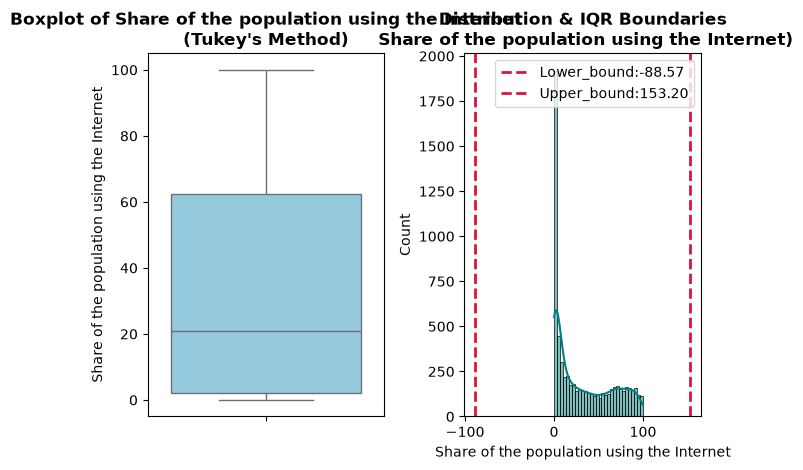

{'Q1': np.float64(2.0915505),
 'Q3': np.float64(62.53535),
 'IQR': np.float64(60.443799500000004),
 'Lower_Bound': np.float64(-88.57414875),
 'Upper_Bound': np.float64(153.20104925),
 'Outliers': Series([], Name: Share of the population using the Internet, dtype: float64)}

In [17]:
#Call the custom outlier detection and visualization function,passing your DataFrame and target column name, then store the returned dictionary in 'iqr_boxplot'
iqr_boxplot = compute_iqr_and_boxplot(Share_with_internet,'Share of the population using the Internet')
#Display the contents of the 'iqr_boxplot' dictionary (quartiles,bounds, and outliers) in your enviroment
iqr_boxplot

In [18]:
def filter_outliers_iqr(df, feature_name):
    #Extract the target feature column and drop any missing (NaN) values to prevent errors during comparisons
    data = df[feature_name].dropna()

    q1 = np.percentile(data,25)
    q3 = np.percentile(data,75)
    iqr_value = q3-q1

    lower_bound = q1- 1.5*iqr_value
    upper_bound = q3+ 1.5*iqr_value
  #Creat a boolean mask (True/False) that identifies rows where the value falls outside Tukey's fences
    #(either  below the lower bound or above the upper bound)
    outlier_condition = (df[feature_name]< lower_bound) | (df[feature_name] > upper_bound)
    #Filter the original DataFrame to isolate and store ONLY the rows containing outliers
    outliers_df = df[outlier_condition]
    #Filter the original DataFrame using the inverse operator(~) to keep ONLY the normal data, effectively removing the outliers
    cleaned_df = df[~outlier_condition]

    print(f"=== Outlier Filtering Report for '{feature_name}'===")
    print(f"* Original Total Rows  : {len(df)}")
    print(f"* Interquartile Range  : {iqr_value:.4f}")
    print(f"* Lower Bound Threshold: {lower_bound:.4f}")
    print(f"* Upper Bound Threshold: {upper_bound:.4f}")
    print(f"* Filtered Outliers Count:{len(outliers_df)}")
    print(f"*Cleaned Data Rows     :{len(cleaned_df)}\n")
    return cleaned_df,outliers_df

In [19]:
filter_outliers = filter_outliers_iqr(Share_with_internet,'Share of the population using the Internet')
filter_outliers

=== Outlier Filtering Report for 'Share of the population using the Internet'===
* Original Total Rows  : 6659
* Interquartile Range  : 60.4438
* Lower Bound Threshold: -88.5741
* Upper Bound Threshold: 153.2010
* Filtered Outliers Count:0
*Cleaned Data Rows     :6659



(           Entity Code  Year  Share of the population using the Internet
 0     Afghanistan  AFG  1990                                    0.000000
 1     Afghanistan  AFG  2001                                    0.004723
 2     Afghanistan  AFG  2002                                    0.004561
 3     Afghanistan  AFG  2003                                    0.087891
 4     Afghanistan  AFG  2004                                    0.105809
 ...           ...  ...   ...                                         ...
 6654     Zimbabwe  ZWE  2020                                   29.298565
 6655     Zimbabwe  ZWE  2021                                   32.592400
 6656     Zimbabwe  ZWE  2022                                   36.256500
 6657     Zimbabwe  ZWE  2023                                   38.674800
 6658     Zimbabwe  ZWE  2024                                   41.642800
 
 [6659 rows x 4 columns],
 Empty DataFrame
 Columns: [Entity, Code, Year, Share of the population using the In

In [20]:
share_internet_mode = Share_with_internet['Share of the population using the Internet'].mode()
share_internet_mode

0    0.0
Name: Share of the population using the Internet, dtype: float64

Data Science Insight

 Skewness != Outliers (A Common Misconception in EDA)
While performing an Exploratory Data Analysis (EDA) in Internet Usage Share data, I encountered a fascinating statistical reality the highlights why 
blindly assuming data properties can lead to misinterpretation:
 1)The Shpae: The data exhibts a clear Right-Skew(Mean = 32.65 vs Median = 20.81)because the majority of observations are heavily clustered at the lower
   end, gradually spreading toward 100%.
 2)The Outlier Reality:Interestingly, despite the significant skewness, calculating Tukey's fences revealed an Upper Boundary of 153.2 while the actual
   maximum data point is 100.0.There are zero statistical outliers in this dataset.
 3)Key Takeaway:Skewness does not imply the presence of outliers.Skewness describes the distributional shape, whereas outliers are extreme values beyond
   bounds. In right-skewed distribitions without outliers, relying soley on the Mean can be misleading-making Median and IQR the robust choicesfor
   central tendency.

In [21]:
#Myanmar specific

myanmar_internet = Share_with_internet[
    (Share_with_internet['Entity'] == 'Myanmar') &
    (Share_with_internet['Year'] >= 1990)]

internet_values = myanmar_internet['Share of the population using the Internet']

IU_internet_myan_mean = internet_values.mean()
IU_internet_myan_median = internet_values.median()
IU_internet_myan_tri = trim_mean(internet_values,0.1)


print('Internet using Myan mean : ',IU_internet_myan_mean)
print('Internet using Myan median :',IU_internet_myan_median)
print('Internet using Myan trimmed mean: ',IU_internet_myan_tri)

Internet using Myan mean :  7.939633095136363
Internet using Myan median : 0.235
Internet using Myan trimmed mean:  5.149087560722222


In [22]:
IU_internet_myan_tri = trim_mean(internet_values,0.2)
print('Internet using Myan trimmed mean: ',IU_internet_myan_tri)

Internet using Myan trimmed mean:  2.8344841658571434


In [23]:
IU_internet_myan_tri = trim_mean(internet_values,0.3)
print('Internet using Myan trimmed mean: ',IU_internet_myan_tri)

Internet using Myan trimmed mean:  1.273437678


In [24]:
MAD_mean = Share_with_internet['Share of the population using the Internet']
mean_result,mad_result = calculate_mad_mean(MAD_mean)
print(f"Data:{MAD_mean}")
print(f"Mean:{mean_result:.2f}")
print(f"Mean Absolute Deviation(MAD):{mad_result:.2f}")

Data:0        0.000000
1        0.004723
2        0.004561
3        0.087891
4        0.105809
          ...    
6654    29.298565
6655    32.592400
6656    36.256500
6657    38.674800
6658    41.642800
Name: Share of the population using the Internet, Length: 6659, dtype: float64
Mean:32.65
Mean Absolute Deviation(MAD):28.86


In [25]:
Myan_MAD_mean = myanmar_internet['Share of the population using the Internet']

mean_result,mad_result = calculate_mad_mean(Myan_MAD_mean)
print(f"Data: {Myan_MAD_mean}")
print(f"Mean: {mean_result:.2f}")
print(f"Mean Absolute Deviation(MAD):{mad_result:.2f}")

Data: 4163     0.000000
4164     0.000152
4165     0.000289
4166     0.000426
4167     0.024064
4168     0.024337
4169     0.065200
4170     0.182048
4171     0.217128
4172     0.220000
4173     0.220000
4174     0.250000
4175     0.980000
4176     1.400000
4177     1.800000
4178     7.400000
4179    10.900000
4180    16.000000
4181    23.621082
4182    29.379000
4183    36.540500
4184    45.447700
Name: Share of the population using the Internet, dtype: float64
Mean: 7.94
Mean Absolute Deviation(MAD):10.39


In [26]:
Myan_MAD_median = myanmar_internet['Share of the population using the Internet']
median_result,mad_result = calculate_mad_median(Myan_MAD_median)
print(f"Data: {Myan_MAD_median}")
print(f"Median:{median_result:.2f}")
print(f"Median Absolute Deviation(MAD):{mad_result:.2f}")

Data: 4163     0.000000
4164     0.000152
4165     0.000289
4166     0.000426
4167     0.024064
4168     0.024337
4169     0.065200
4170     0.182048
4171     0.217128
4172     0.220000
4173     0.220000
4174     0.250000
4175     0.980000
4176     1.400000
4177     1.800000
4178     7.400000
4179    10.900000
4180    16.000000
4181    23.621082
4182    29.379000
4183    36.540500
4184    45.447700
Name: Share of the population using the Internet, dtype: float64
Median:0.23
Median Absolute Deviation(MAD):0.23


===Statistical Summary for 'Share of the population using the Internet'(IQR Method)===
* 25th Percentile (Q1) : 0.0346
* 75th Percentile (Q3) : 10.0250
* Interquartile Range  :9.9904
* Lower Bound          : -14.9511
* Upper Bound          : 25.0107
* Total Outliers Count : 3
* Outlier Value   : [29.379, 36.5405, 45.4477]



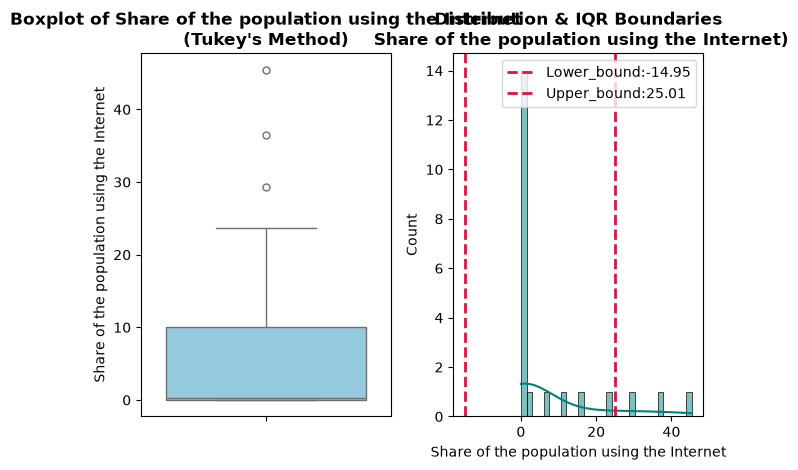

{'Q1': np.float64(0.034553044),
 'Q3': np.float64(10.025),
 'IQR': np.float64(9.990446956),
 'Lower_Bound': np.float64(-14.951117389999999),
 'Upper_Bound': np.float64(25.010670433999998),
 'Outliers': 4182    29.3790
 4183    36.5405
 4184    45.4477
 Name: Share of the population using the Internet, dtype: float64}

In [27]:
Myan_iqr_boxplot = compute_iqr_and_boxplot(myanmar_internet,'Share of the population using the Internet')
Myan_iqr_boxplot

In [28]:
print(myanmar_internet['Share of the population using the Internet'].describe())

count    22.000000
mean      7.939633
std      13.576813
min       0.000000
25%       0.034553
50%       0.235000
75%      10.025000
max      45.447700
Name: Share of the population using the Internet, dtype: float64


In [29]:
myan_mode = myanmar_internet['Share of the population using the Internet'].mode()
myan_mode

0    0.22
Name: Share of the population using the Internet, dtype: float64

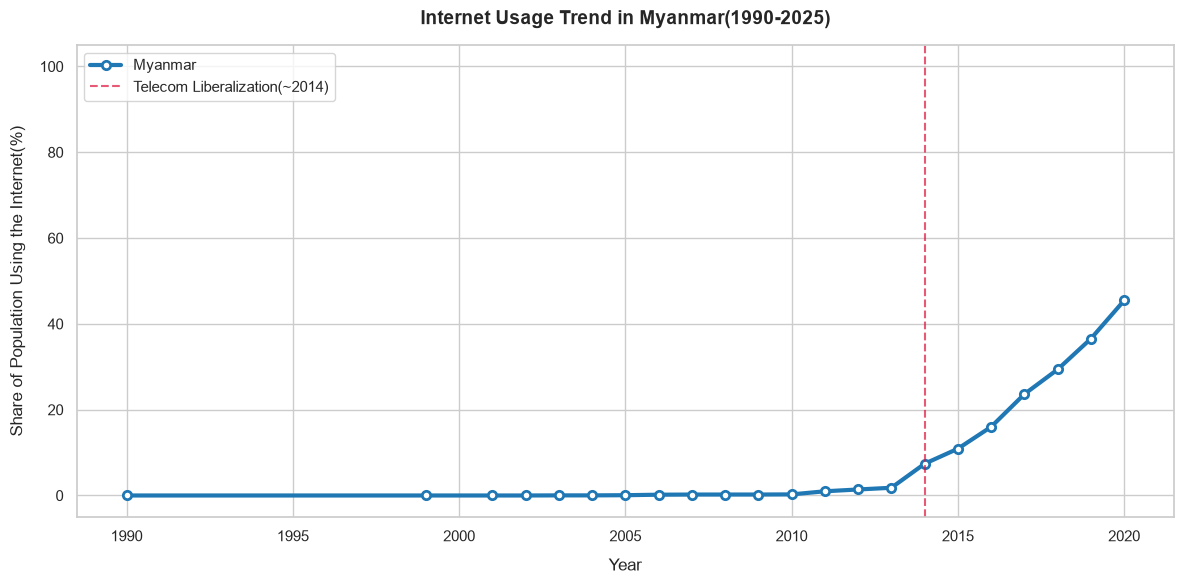

<Figure size 640x480 with 0 Axes>

In [36]:
df_myanmar_trend = Share_with_internet[Share_with_internet['Entity'] == 'Myanmar'].sort_values('Year')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12,6))

plt.plot(df_myanmar_trend['Year'],
        df_myanmar_trend['Share of the population using the Internet'],color = '#1f77b4',linewidth = 3,marker = 'o',markersize = 6,
         markerfacecolor='white',markeredgewidth = 2, label = 'Myanmar')
plt.title ('Internet Usage Trend in Myanmar(1990-2025)',fontsize = 14, fontweight ='bold',pad=15)
plt.xlabel('Year',fontsize = 12,labelpad = 10)
plt.ylabel('Share of Population Using the Internet(%)',fontsize = 12, labelpad = 10)

plt.xticks(np.arange(1990,2025,5))
plt.ylim(-5,105)

plt.axvline(x=2014,color='crimson',linestyle ='--',alpha = 0.7,label = 'Telecom Liberalization(~2014)')
plt.legend(loc = 'upper left',frameon=True,fontsize=11)
plt.tight_layout()
plt.show()
plt.savefig('Internet Usage Trend in Myanmar (1990-2025).png')

In [31]:
#Thailand specific
thailand_internet = Share_with_internet[
    (Share_with_internet['Entity'] == 'Thailand') &
    (Share_with_internet['Year'] >= 1990)]

internet_values = thailand_internet['Share of the population using the Internet']

IU_internet_thai_mean = internet_values.mean()
IU_internet_thai_median = internet_values.median()
IU_internet_thai_tri = trim_mean(internet_values,0.1)


print('Internet using Thai mean : ',IU_internet_thai_mean)
print('Internet using Thai median :',IU_internet_thai_median)
print('Internet using Thai trimmed mean: ',IU_internet_thai_tri)

Internet using Thai mean :  27.497856202857143
Internet using Thai median : 18.2
Internet using Thai trimmed mean:  23.932582272413796


===Statistical Summary for 'Share of the population using the Internet'(IQR Method)===
* 25th Percentile (Q1) : 1.7600
* 75th Percentile (Q3) : 43.4105
* Interquartile Range  :41.6505
* Lower Bound          : -60.7158
* Upper Bound          : 105.8864
* Total Outliers Count : 0
* Outlier 



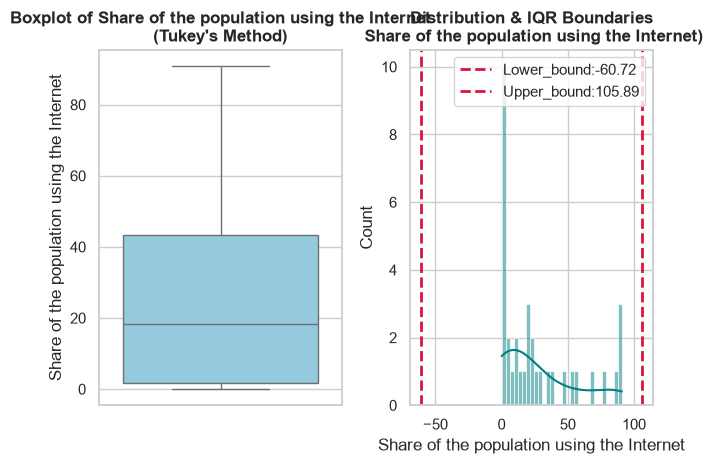

{'Q1': np.float64(1.7600000000000002),
 'Q3': np.float64(43.4105475),
 'IQR': np.float64(41.6505475),
 'Lower_Bound': np.float64(-60.715821250000005),
 'Upper_Bound': np.float64(105.88636875),
 'Outliers': Series([], Name: Share of the population using the Internet, dtype: float64)}

In [32]:
Thai_iqr_boxplot = compute_iqr_and_boxplot(thailand_internet,'Share of the population using the Internet')
Thai_iqr_boxplot

In [33]:
print(thailand_internet['Share of the population using the Internet'].describe())

count    35.000000
mean     27.497856
std      30.162548
min       0.000000
25%       1.760000
50%      18.200000
75%      43.410547
max      90.867190
Name: Share of the population using the Internet, dtype: float64


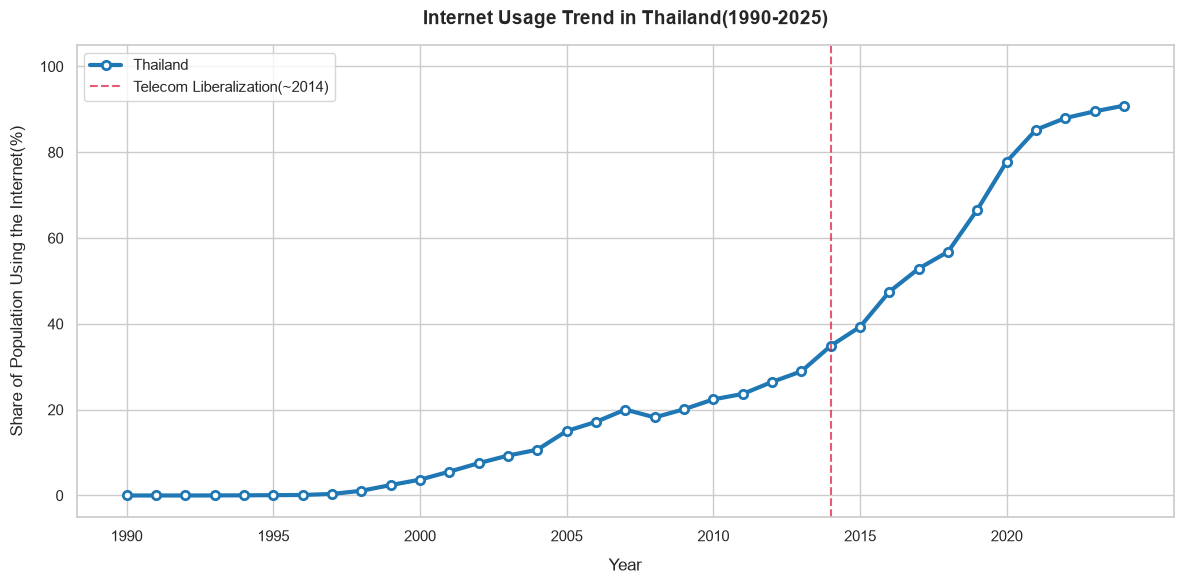

<Figure size 640x480 with 0 Axes>

In [35]:
df_thailand_trend = Share_with_internet[Share_with_internet['Entity'] == 'Thailand'].sort_values('Year')

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12,6))

plt.plot(df_thailand_trend['Year'],
        df_thailand_trend['Share of the population using the Internet'],color = '#1f77b4',linewidth = 3,marker = 'o',markersize = 6,
         markerfacecolor='white',markeredgewidth = 2, label = 'Thailand')
plt.title ('Internet Usage Trend in Thailand(1990-2025)',fontsize = 14, fontweight ='bold',pad=15)
plt.xlabel('Year',fontsize = 12,labelpad = 10)
plt.ylabel('Share of Population Using the Internet(%)',fontsize = 12, labelpad = 10)

plt.xticks(np.arange(1990,2025,5))
plt.ylim(-5,105)

plt.axvline(x=2014,color='crimson',linestyle ='--',alpha = 0.7,label = 'Telecom Liberalization(~2014)')
plt.legend(loc = 'upper left',frameon=True,fontsize=11)
plt.tight_layout()
plt.show()
plt.savefig('Internet Usage Trend in Thailand (1990-2025')